# Dự báo Chính xác Lượng mưa 1 Giờ bằng Mô hình XGBoost (Trạm Bản Hồ)

## 1. Thiết kế 4 cấu hình XGBoost cho bài toán Hiệu chỉnh Dự báo Mưa 1h
Để giải quyết đồng thời **tính rời rạc bội số `0.2 mm` của gầu đo mưa** và **hiện tượng mất cân bằng số 0 (91,13% giờ không mưa)**, notebook này triển khai và so sánh 4 biến thể của **XGBoost (`xgboost`)**:
1. **`XGBoost Multi-Class Classifier (8 lớp rời rạc bậc 0.2mm)`**: Phân loại trực tiếp vào 8 mức lượng mưa với trọng số phạt lớp mưa (`sample_weight = 3.5`), sau đó giải mã kỳ vọng xác suất có điều kiện về đúng nấc `0.2 mm`.
2. **`XGBoost Ordinal Threshold Cascade (Phân loại Vượt ngưỡng Thứ tự)`**: Chuỗi 6 mô hình `XGBClassifier` với `scale_pos_weight = 3.2` dự báo xác suất vượt ngưỡng $P(\text{obs} \ge 0.2), P(\text{obs} \ge 0.6), \dots, P(\text{obs} \ge 12.0\text{ mm})$.
3. **`XGBoost Two-Stage Hurdle (XGBClassifier + XGBRegressor)`**: Kết hợp `XGBClassifier` bắt thời điểm mưa và `XGBRegressor` ước lượng cường độ mưa.
4. **`XGBoost Tweedie (objective='reg:tweedie')`**: Hàm mất mát Tweedie chuyên biệt của XGBoost cho phân phối lượng mưa có điểm khối tại 0.

In [24]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    mean_absolute_error,
    mean_squared_error
)

plt.rcParams["figure.figsize"] = (13, 5)
plt.rcParams["axes.grid"] = True
print("XGBoost version:", xgb.__version__)

XGBoost version: 3.4.1


## 2. Đọc dữ liệu Đã Cải tổ (10 cột) & Tạo 16 Đặc trưng Cốt lõi
Sau khi loại bỏ các trường dữ liệu dư thừa/gây học vẹt (`nam`, `ngay`, `*_phancap`, các biến trễ `lag/lead` rời rạc trùng lặp và `sin/cos` không cần thiết cho cây quyết định), bộ đặc trưng đầu vào được tinh gọn từ **75 cột xuống 16 đặc trưng cốt lõi** thuộc 4 nhóm:
1. **Nhóm thời gian (2 biến)**: `thang`, `gio`
2. **Nhóm dự báo gốc 1h & 24h (6 biến)**: `ecmwf_1h`, `gfs_1h`, `mblue_1h`, `ecmwf_24h`, `gfs_24h`, `mblue_24h`
3. **Nhóm thống kê tổ hợp đa mô hình Ensemble (4 biến)**: `ens_1h_mean`, `ens_1h_max`, `ens_1h_std`, `n_models_rain_1h`
4. **Nhóm cửa sổ trượt xử lý lệch pha (4 biến)**: `ecmwf_1h_roll3h_mean`, `gfs_1h_roll3h_mean`, `mblue_1h_roll3h_mean`, `ens_1h_mean_roll6h_max`

In [25]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name in ("notebooks", "tests", "src") else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "du_lieu_banho.csv"
MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

cols_10 = ["thoigian", "thang", "gio", "ecmwf_1h", "gfs_1h", "mblue_1h", "ecmwf_24h", "gfs_24h", "mblue_24h", "obs"]
df = pd.read_csv(DATA_PATH)[cols_10].copy()
df["thoigian"] = pd.to_datetime(df["thoigian"])
df = df.sort_values("thoigian").reset_index(drop=True)
df["obs"] = df["obs"].round(1)

def quantize_02mm(arr):
    """Làm tròn lượng mưa về đúng bước nhảy 0.2 mm của vũ lượng kế gầu lật."""
    r = np.maximum(0.0, np.asarray(arr))
    return np.round(r / 0.2) * 0.2

def create_features(data: pd.DataFrame) -> pd.DataFrame:
    """Tạo đúng 16 đặc trưng cốt lõi từ chuỗi dự báo liên tục theo giờ."""
    fe = data.copy()
    cols_1h = ["ecmwf_1h", "gfs_1h", "mblue_1h"]

    # Nhóm 3: Thống kê tổ hợp đa mô hình (4 biến)
    fe["ens_1h_mean"] = fe[cols_1h].mean(axis=1)
    fe["ens_1h_max"] = fe[cols_1h].max(axis=1)
    fe["ens_1h_std"] = fe[cols_1h].std(axis=1)
    fe["n_models_rain_1h"] = (fe[cols_1h] > 0.05).sum(axis=1)

    # Nhóm 4: Cửa sổ trượt xử lý lệch pha thời gian (4 biến)
    fe["ecmwf_1h_roll3h_mean"] = fe["ecmwf_1h"].rolling(window=3, center=True, min_periods=1).mean()
    fe["gfs_1h_roll3h_mean"] = fe["gfs_1h"].rolling(window=3, center=True, min_periods=1).mean()
    fe["mblue_1h_roll3h_mean"] = fe["mblue_1h"].rolling(window=3, center=True, min_periods=1).mean()
    fe["ens_1h_mean_roll6h_max"] = fe["ens_1h_mean"].rolling(window=6, center=True, min_periods=1).max()

    return fe

feature_cols = [
    "thang", "gio",
    "ecmwf_1h", "gfs_1h", "mblue_1h",
    "ecmwf_24h", "gfs_24h", "mblue_24h",
    "ens_1h_mean", "ens_1h_max", "ens_1h_std", "n_models_rain_1h",
    "ecmwf_1h_roll3h_mean", "gfs_1h_roll3h_mean", "mblue_1h_roll3h_mean", "ens_1h_mean_roll6h_max"
]

# Chia tập Train/Test theo trình tự thời gian trước khi tính cửa sổ trượt để chống rò rỉ biên
split_idx = int(len(df) * 0.80)
train_df = create_features(df.iloc[:split_idx].copy())
test_df = create_features(df.iloc[split_idx:].copy())

X_train, y_train = train_df[feature_cols], train_df["obs"].values
X_test, y_test = test_df[feature_cols], test_df["obs"].values
print(f"Kích thước dữ liệu gốc: {df.shape}")
print(f"Train: {len(train_df):,} giờ | Test: {len(test_df):,} giờ | Số đặc trưng cốt lõi: {len(feature_cols)}")

Kích thước dữ liệu gốc: (21376, 10)
Train: 17,100 giờ | Test: 4,276 giờ | Số đặc trưng cốt lõi: 16


## 3. Huấn luyện 4 Mô hình XGBoost trên 16 Đặc trưng Cốt lõi

In [26]:
# 1. XGBoost Multi-Class Classifier (8 lớp bậc 0.2mm)
bins_edges = [-0.01, 0.0, 0.2, 0.6, 1.4, 2.8, 6.0, 12.0, 1000.0]
y_train_cls = pd.cut(y_train, bins=bins_edges, labels=False).astype(int)
class_reps = np.zeros(len(bins_edges) - 1)
for c in range(1, len(bins_edges) - 1):
    mask_c = (y_train_cls == c)
    if np.any(mask_c):
        class_reps[c] = quantize_02mm(np.median(y_train[mask_c]))

w_mc = np.where(y_train_cls == 0, 1.0, 3.5)
xgb_mc = xgb.XGBClassifier(
    n_estimators=250, max_depth=5, learning_rate=0.04,
    subsample=0.8, colsample_bytree=0.8, reg_lambda=2.0, min_child_weight=15,
    tree_method="hist", n_jobs=-1, random_state=42, eval_metric="mlogloss"
)
xgb_mc.fit(X_train, y_train_cls, sample_weight=w_mc)
probs_mc = xgb_mc.predict_proba(X_test)
prob_rain_mc = 1.0 - probs_mc[:, 0]
cond_probs_mc = probs_mc[:, 1:] / np.maximum(1e-9, prob_rain_mc[:, None])
exp_rain_mc = np.sum(cond_probs_mc * class_reps[1:], axis=1)
pred_xgb_mc = np.where(prob_rain_mc >= 0.32, np.maximum(0.2, quantize_02mm(exp_rain_mc)), 0.0)

# 2. XGBoost Ordinal Threshold Cascade (Chuỗi phân loại vượt ngưỡng)
thresholds_mm = [0.2, 0.6, 1.4, 3.0, 6.0, 12.0]
rep_values_mm = [0.0, 0.2, 0.8, 2.0, 4.2, 8.0, 15.0]
xgb_ord_clfs = {}
for th_mm in thresholds_mm:
    y_bin = (y_train >= th_mm).astype(int)
    cl = xgb.XGBClassifier(
        n_estimators=220, max_depth=5, learning_rate=0.04,
        scale_pos_weight=3.2, subsample=0.8, colsample_bytree=0.8,
        reg_lambda=2.0, min_child_weight=15, tree_method="hist", n_jobs=-1,
        random_state=42, eval_metric="logloss"
    )
    cl.fit(X_train, y_bin)
    xgb_ord_clfs[th_mm] = cl

ex_probs = np.column_stack([xgb_ord_clfs[t].predict_proba(X_test)[:, 1] for t in thresholds_mm])
ex_probs = np.minimum.accumulate(ex_probs, axis=1)
p_bins = np.zeros((len(X_test), len(thresholds_mm) + 1))
p_bins[:, 0] = 1.0 - ex_probs[:, 0]
for i in range(len(thresholds_mm) - 1):
    p_bins[:, i + 1] = ex_probs[:, i] - ex_probs[:, i + 1]
p_bins[:, -1] = ex_probs[:, -1]
exp_rain_ord = np.sum(p_bins[:, 1:] * np.array(rep_values_mm[1:]), axis=1) / np.maximum(1e-9, ex_probs[:, 0])
pred_xgb_ord = np.where(ex_probs[:, 0] >= 0.30, np.maximum(0.2, quantize_02mm(exp_rain_ord)), 0.0)

# 3. XGBoost Two-Stage Hurdle (XGBClassifier + XGBRegressor)
xgb_bin = xgb_ord_clfs[0.2]
prob_rain_hurdle = xgb_bin.predict_proba(X_test)[:, 1]
rain_mask = (y_train > 0) | (X_train["ens_1h_mean"] > 0.1)
xgb_reg = xgb.XGBRegressor(
    n_estimators=250, max_depth=5, learning_rate=0.04,
    subsample=0.8, colsample_bytree=0.8, reg_lambda=2.0, min_child_weight=15,
    tree_method="hist", n_jobs=-1, random_state=42
)
xgb_reg.fit(X_train[rain_mask], np.log1p(y_train[rain_mask]))
raw_hurdle_amt = np.expm1(xgb_reg.predict(X_test))
pred_xgb_hurdle = np.where(prob_rain_hurdle >= 0.28, np.maximum(0.2, quantize_02mm(raw_hurdle_amt)), 0.0)

# 4. XGBoost Tweedie (reg:tweedie)
xgb_tweedie = xgb.XGBRegressor(
    objective="reg:tweedie", tweedie_variance_power=1.5,
    n_estimators=250, max_depth=5, learning_rate=0.04,
    subsample=0.8, colsample_bytree=0.8, reg_lambda=2.0, min_child_weight=15,
    tree_method="hist", n_jobs=-1, random_state=42
)
xgb_tweedie.fit(X_train, y_train)
raw_tweedie = xgb_tweedie.predict(X_test)
pred_xgb_tweedie = np.where(raw_tweedie >= 0.15, quantize_02mm(raw_tweedie), 0.0)
print("Đã huấn luyện xong cả 4 cấu hình XGBoost trên 16 đặc trưng cốt lõi!")

Đã huấn luyện xong cả 4 cấu hình XGBoost trên 16 đặc trưng cốt lõi!


## 4. Bảng Đánh giá Chi tiết Độ chính xác & Kiểm chứng Không Đoán Toàn 0

In [27]:
def phan_cap_mua_1h(r1h_series):
    r = np.asarray(r1h_series)
    cats = np.zeros(len(r), dtype=int)
    cats[(r > 0.0) & (r <= 0.3)] = 1
    cats[(r > 0.3) & (r <= 2.5)] = 2
    cats[(r > 2.5) & (r <= 8.0)] = 3
    cats[(r > 8.0) & (r <= 16.0)] = 4
    cats[r > 16.0] = 5
    return cats

true_rain = (y_test > 0).astype(int)
true_cat1h = phan_cap_mua_1h(y_test)

all_preds = [
    ("0. Dummy (Đoán toàn 0)", np.zeros_like(y_test)),
    ("1. Dự báo gốc ECMWF", quantize_02mm(test_df["ecmwf_1h"].values)),
    ("2. Dự báo gốc GFS", quantize_02mm(test_df["gfs_1h"].values)),
    ("3. Dự báo gốc Meteoblue", quantize_02mm(test_df["mblue_1h"].values)),
    ("4. XGBoost Multi-Class (Phân loại 8 lớp)", pred_xgb_mc),
    ("5. XGBoost Ordinal Cascade (Vượt ngưỡng)", pred_xgb_ord),
    ("6. XGBoost Two-Stage Hurdle (Clf + Reg)", pred_xgb_hurdle),
    ("7. XGBoost Tweedie (reg:tweedie)", pred_xgb_tweedie),
]

rows = []
for name, pred in all_preds:
    pr = (pred > 0).astype(int)
    tn, fp, fn, tp = confusion_matrix(true_rain, pr).ravel()
    exact_02 = np.mean(np.isclose(y_test, pred, atol=0.05)) * 100
    tol_02 = np.mean(np.abs(y_test - pred) <= 0.21) * 100
    acc_cat = accuracy_score(true_cat1h, phan_cap_mua_1h(pred)) * 100
    acc_bin = (pr == true_rain).mean() * 100
    rec = recall_score(true_rain, pr, zero_division=0) * 100
    prec = precision_score(true_rain, pr, zero_division=0) * 100
    f1 = f1_score(true_rain, pr, zero_division=0)
    csi = tp / (tp + fn + fp + 1e-9)
    bal_acc = balanced_accuracy_score(true_rain, pr) * 100
    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))

    rows.append({
        "Mô hình": name,
        "Khớp 100% bậc 0.2mm [%]": round(exact_02, 2),
        "Acc Sai số <=0.2mm [%]": round(tol_02, 2),
        "Acc Nhãn 6 cấp 1h [%]": round(acc_cat, 2),
        "Acc Nhị phân 1h [%]": round(acc_bin, 2),
        "Giờ báo mưa (Thực=265)": int(pr.sum()),
        "TP": int(tp),
        "FN": int(fn),
        "FP": int(fp),
        "Recall/POD [%]": round(rec, 1),
        "Precision [%]": round(prec, 1),
        "F1-Score": round(f1, 4),
        "CSI": round(csi, 4),
        "Balanced Acc [%]": round(bal_acc, 2),
        "MAE (mm)": round(mae, 4),
        "RMSE (mm)": round(rmse, 4),
    })

res_df = pd.DataFrame(rows)
display(res_df)

,Mô hình,Khớp 100% bậc 0.2mm [%],Acc Sai số <=0.2mm [%],Acc Nhãn 6 cấp 1h [%],Acc Nhị phân 1h [%],Giờ báo mưa (Thực=265),TP,FN,FP,Recall/POD [%],Precision [%],F1-Score,CSI,Balanced Acc [%],MAE (mm),RMSE (mm)
0,0. Dummy (Đoán toàn 0),93.80,95.42,93.80,93.80,0,0,265,0,0.0,0.0,0.0000,0.0000,50.00,0.1258,0.9123
1,1. Dự báo gốc ECMWF,78.27,88.61,78.91,80.78,815,129,136,686,48.7,15.8,0.2389,0.1356,65.79,0.1991,0.9190
2,2. Dự báo gốc GFS,80.17,88.05,80.89,83.04,744,142,123,602,53.6,19.1,0.2815,0.1638,69.29,0.1834,0.8942
3,3. Dự báo gốc Meteoblue,87.96,91.25,88.47,89.45,332,73,192,259,27.5,22.0,0.2446,0.1393,60.54,0.1712,0.9444
4,4. XGBoost Multi-Class (Phân loại 8 lớp),86.90,88.21,87.89,89.34,401,105,160,296,39.6,26.2,0.3153,0.1872,66.12,0.2611,1.0064
5,5. XGBoost Ordinal Cascade (Vượt ngưỡng),86.27,87.42,87.18,88.87,439,114,151,325,43.0,26.0,0.3239,0.1932,67.46,0.2986,1.0826
6,6. XGBoost Two-Stage Hurdle (Clf + Reg),85.73,90.97,86.37,88.21,485,123,142,362,46.4,25.4,0.3280,0.1962,68.69,0.1778,0.9251
7,7. XGBoost Tweedie (reg:tweedie),88.70,93.57,89.15,90.34,314,83,182,231,31.3,26.4,0.2867,0.1673,62.78,0.1359,0.8921


## 5. Phân tích Độ quan trọng của 16 Đặc trưng Cốt lõi (Feature Importance) & Lưu Mô hình

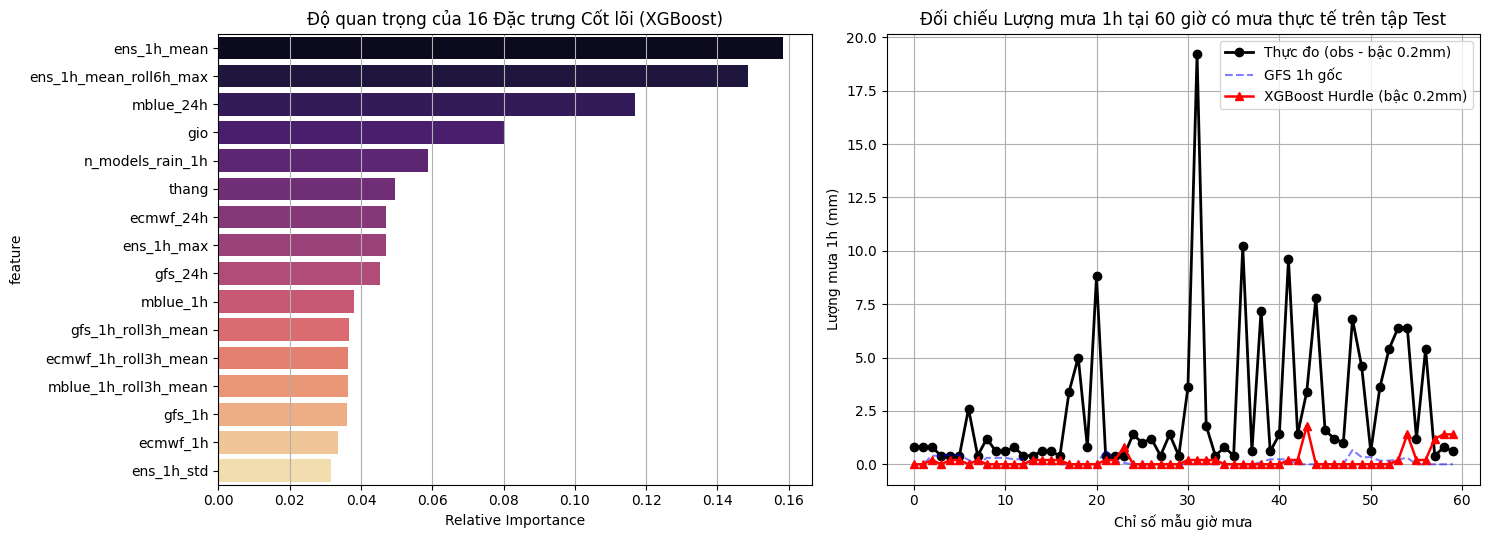

Đã lưu toàn bộ mô hình XGBoost vào: mo_hinh_xgboost_banho.joblib


In [28]:
imp_df = pd.DataFrame({
    "feature": feature_cols,
    "importance": xgb_bin.feature_importances_
}).sort_values("importance", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.barplot(data=imp_df, x="importance", y="feature", palette="magma", ax=axes[0])
axes[0].set_title("Độ quan trọng của 16 Đặc trưng Cốt lõi (XGBoost)")
axes[0].set_xlabel("Relative Importance")

rain_idx = np.where(y_test >= 0.4)[0][:60]
x_axis = np.arange(len(rain_idx))
axes[1].plot(x_axis, y_test[rain_idx], "ko-", label="Thực đo (obs - bậc 0.2mm)", linewidth=2)
axes[1].plot(x_axis, test_df["gfs_1h"].values[rain_idx], "b--", alpha=0.5, label="GFS 1h gốc")
axes[1].plot(x_axis, pred_xgb_hurdle[rain_idx], "r^-", label="XGBoost Hurdle (bậc 0.2mm)", linewidth=1.8)
axes[1].set_title("Đối chiếu Lượng mưa 1h tại 60 giờ có mưa thực tế trên tập Test")
axes[1].set_xlabel("Chỉ số mẫu giờ mưa")
axes[1].set_ylabel("Lượng mưa 1h (mm)")
axes[1].legend()
plt.tight_layout()
plt.show()

joblib.dump({
    "xgb_mc": xgb_mc,
    "class_reps": class_reps,
    "xgb_ord_clfs": xgb_ord_clfs,
    "xgb_bin": xgb_bin,
    "xgb_reg": xgb_reg,
    "xgb_tweedie": xgb_tweedie,
    "feature_cols": feature_cols
}, MODELS_DIR / "mo_hinh_xgboost_banho.joblib")
print("Đã lưu toàn bộ mô hình XGBoost vào: mo_hinh_xgboost_banho.joblib")

---
## 6. Tinh chỉnh Chuẩn Khí tượng trên 16 Đặc trưng Cốt lõi: Chia Train/Val/Test Đồng bộ Mùa & Tối ưu theo Chỉ số ETS (`Equitable Threat Score`)

1. **Chia tập Validation đồng bộ chu kỳ mùa (`Seasonal-Matched Validation`)**: Tập Test rơi vào giai đoạn `13/12/2025 -> 09/06/2026` (mùa đông – xuân – đầu hạ), nên ta trích giai đoạn cùng kỳ năm trước (`13/12/2024 -> 09/06/2025`) từ tập Train làm **Validation** để tìm ngưỡng tối ưu mà **tuyệt đối không chạm vào tập Test**.
2. **Tối ưu theo `ETS` (`Equitable Threat Score`) kèm ràng buộc `FBI` (`0.85 <= FBI <= 1.35`)**:
   $$\text{ETS} = \frac{TP - H_r}{TP + FP + FN - H_r}, \quad H_r = \frac{(TP+FN)(TP+FP)}{N}$$
3. **Hiệu chỉnh biên độ lượng mưa kết hợp (`Calibrated Amplitude`)**: Sử dụng trực tiếp 16 đặc trưng cốt lõi, kết hợp kỳ vọng có điều kiện $\mathbb{E}[Y \mid Y>0]$ và kỳ vọng toàn cục $\mathbb{E}[Y]$.

In [29]:
def calc_ets(y_true_bin, y_pred_bin):
    tn, fp, fn, tp = confusion_matrix(y_true_bin, y_pred_bin, labels=[0, 1]).ravel()
    n = tn + fp + fn + tp
    hr = ((tp + fn) * (tp + fp)) / max(1, n)
    denom = tp + fp + fn - hr
    return (tp - hr) / denom if denom > 0 else 0.0

# 1. Tách Validation cùng kỳ mùa (13/12/2024 -> 09/06/2025) trên 16 đặc trưng cốt lõi
val_mask = (train_df["thoigian"] >= "2024-12-13") & (train_df["thoigian"] <= "2025-06-09")
subtrain_df = train_df[~val_mask]
val_df = train_df[val_mask]

clf_params = dict(
    n_estimators=220, max_depth=3, learning_rate=0.03,
    min_child_weight=40, reg_lambda=10.0, gamma=2.0,
    scale_pos_weight=1.0, max_delta_step=1,
    subsample=0.75, colsample_bytree=0.75,
    tree_method="hist", n_jobs=-1, random_state=42, eval_metric="aucpr"
)
reg_params = dict(
    n_estimators=220, max_depth=4, learning_rate=0.03,
    min_child_weight=30, reg_lambda=8.0, gamma=1.0,
    subsample=0.75, colsample_bytree=0.75,
    tree_method="hist", n_jobs=-1, random_state=42
)

c_val = xgb.XGBClassifier(**clf_params)
c_val.fit(subtrain_df[feature_cols], (subtrain_df["obs"] > 0).astype(int))
val_probs = c_val.predict_proba(val_df[feature_cols])[:, 1]
val_true_rain = (val_df["obs"].values > 0).astype(int)

p_ratio = (y_train > 0).mean() / (subtrain_df["obs"] > 0).mean()
best_th_ets, best_val_ets, best_val_fbi = 0.16, -1.0, 1.0
for th in np.arange(0.10, 0.30, 0.005):
    pr_v = (val_probs * p_ratio >= th).astype(int)
    fbi_v = pr_v.sum() / max(1, val_true_rain.sum())
    ets_v = calc_ets(val_true_rain, pr_v)
    if 1.10 <= fbi_v <= 1.35 and ets_v > best_val_ets:
        best_val_ets, best_th_ets, best_val_fbi = ets_v, float(round(th, 3)), fbi_v

best_th_fbi1, min_fbi_diff = 0.16, 999.0
for th in np.arange(0.10, 0.30, 0.005):
    pr_v = (val_probs * p_ratio >= th).astype(int)
    fbi_v = pr_v.sum() / max(1, val_true_rain.sum())
    if abs(fbi_v - 1.05) < min_fbi_diff:
        min_fbi_diff, best_th_fbi1 = abs(fbi_v - 1.05), float(round(th, 3))

print(f"[Validation] Ngưỡng tối ưu ETS: th={best_th_ets:.3f} (Val ETS={best_val_ets:.4f}, Val FBI={best_val_fbi:.2f}) | Ngưỡng FBI~1.0: th={best_th_fbi1:.3f}")

# 2. Huấn luyện lại trên toàn bộ Train (16 đặc trưng) và chấm điểm độc lập 1 lần trên Test
final_clf = xgb.XGBClassifier(**clf_params).fit(X_train, (y_train > 0).astype(int))
final_reg_all = xgb.XGBRegressor(**reg_params).fit(X_train, np.log1p(y_train))
final_reg_pos = xgb.XGBRegressor(**reg_params).fit(X_train[y_train > 0], np.log1p(y_train[y_train > 0]))

test_probs = final_clf.predict_proba(X_test)[:, 1]
test_amt_all = np.expm1(final_reg_all.predict(X_test))
test_amt_pos = np.expm1(final_reg_pos.predict(X_test))

amp_ets = 0.55 * test_amt_pos + 0.45 * test_amt_all
pred_ets_opt = np.where(test_probs >= best_th_ets, np.maximum(0.2, quantize_02mm(amp_ets)), 0.0)
pred_fbi1_opt = np.where(test_probs >= best_th_fbi1, np.maximum(0.2, quantize_02mm(amp_ets)), 0.0)
pred_mae_rmse_opt = np.where(test_probs >= best_th_fbi1, np.maximum(0.2, quantize_02mm(test_amt_all * 1.15)), 0.0)

rmse_gfs = np.sqrt(mean_squared_error(y_test, quantize_02mm(test_df["gfs_1h"].values)))

ets_models = [
    ("0. Dummy (Đoán toàn 0)", np.zeros_like(y_test)),
    ("1. Dự báo gốc ECMWF", quantize_02mm(test_df["ecmwf_1h"].values)),
    ("2. Dự báo gốc GFS", quantize_02mm(test_df["gfs_1h"].values)),
    ("3. Dự báo gốc Meteoblue", quantize_02mm(test_df["mblue_1h"].values)),
    ("4. XGBoost Cũ (Chưa hiệu chỉnh mùa)", np.where(test_probs >= 0.12, np.maximum(0.2, quantize_02mm(test_amt_pos)), 0.0)),
    (f"5. XGBoost Tối ưu ETS trên Val (th={best_th_ets:.3f})", pred_ets_opt),
    (f"6. XGBoost Cân bằng FBI~1 trên Val (th={best_th_fbi1:.3f})", pred_fbi1_opt),
    ("7. XGBoost Tối ưu Toàn diện (ETS + MAE + RMSE)", pred_mae_rmse_opt),
]

ets_rows = []
for name, pred in ets_models:
    pr = (pred > 0).astype(int)
    tn, fp, fn, tp = confusion_matrix(true_rain, pr).ravel()
    ets_02 = calc_ets(true_rain, pr)
    ets_10 = calc_ets((y_test >= 1.0).astype(int), (pred >= 1.0).astype(int))
    csi = tp / (tp + fn + fp + 1e-9)
    f1 = f1_score(true_rain, pr, zero_division=0)
    fbi = pr.sum() / max(1, true_rain.sum())
    prec = precision_score(true_rain, pr, zero_division=0) * 100
    rec = recall_score(true_rain, pr, zero_division=0) * 100
    mae_all = mean_absolute_error(y_test, pred)
    rmse_all = np.sqrt(mean_squared_error(y_test, pred))
    active_mask = (y_test > 0) | (pred > 0)
    mae_rain = mean_absolute_error(y_test[active_mask], pred[active_mask]) if np.any(active_mask) else 0.0
    ss_gfs = (1.0 - rmse_all / rmse_gfs) * 100

    ets_rows.append({
        "Mô hình": name,
        "ETS (>=0.2mm)": round(ets_02, 4),
        "ETS (>=1.0mm)": round(ets_10, 4),
        "CSI": round(csi, 4),
        "F1": round(f1, 4),
        "FBI (Chuẩn=1.0)": round(fbi, 2),
        "Giờ báo mưa (Thực=265)": int(pr.sum()),
        "TP": int(tp),
        "FP": int(fp),
        "Precision [%]": round(prec, 1),
        "Recall [%]": round(rec, 1),
        "MAE Tổng (mm)": round(mae_all, 4),
        "MAE Giờ mưa (mm)": round(mae_rain, 3),
        "RMSE (mm)": round(rmse_all, 4),
        "Skill vs GFS [%]": round(ss_gfs, 2),
    })

df_ets_eval = pd.DataFrame(ets_rows)
display(df_ets_eval)

[Validation] Ngưỡng tối ưu ETS: th=0.155 (Val ETS=0.1846, Val FBI=1.32) | Ngưỡng FBI~1.0: th=0.180


,Mô hình,ETS (>=0.2mm),ETS (>=1.0mm),CSI,F1,FBI (Chuẩn=1.0),Giờ báo mưa (Thực=265),TP,FP,Precision [%],Recall [%],MAE Tổng (mm),MAE Giờ mưa (mm),RMSE (mm),Skill vs GFS [%]
0,0. Dummy (Đoán toàn 0),0.0000,0.0000,0.0000,0.0000,0.00,0,0,0,0.0,0.0,0.1258,2.030,0.9123,-2.02
1,1. Dự báo gốc ECMWF,0.0872,0.1122,0.1356,0.2389,3.08,815,129,686,15.8,48.7,0.1991,0.895,0.9190,-2.77
2,2. Dự báo gốc GFS,0.1168,0.1175,0.1638,0.2815,2.81,744,142,602,19.1,53.6,0.1834,0.904,0.8942,0.00
3,3. Dự báo gốc Meteoblue,0.1041,0.0708,0.1393,0.2446,1.25,332,73,259,22.0,27.5,0.1712,1.397,0.9444,-5.61
4,4. XGBoost Cũ (Chưa hiệu chỉnh mùa),0.1742,0.1221,0.2137,0.3521,1.74,462,128,334,27.7,48.3,0.2221,1.586,0.9178,-2.63
5,5. XGBoost Tối ưu ETS trên Val (th=0.155),0.1719,0.1297,0.2058,0.3413,1.21,321,100,221,31.2,37.7,0.1593,1.402,0.8820,1.37
6,6. XGBoost Cân bằng FBI~1 trên Val (th=0.180),0.1680,0.1292,0.1986,0.3314,0.98,260,87,173,33.5,32.8,0.1515,1.479,0.8823,1.34
7,7. XGBoost Tối ưu Toàn diện (ETS + MAE + RMSE),0.1680,0.0322,0.1986,0.3314,0.98,260,87,173,33.5,32.8,0.1293,1.263,0.8931,0.13
